# ConformAtlas Python API walkthrough: adenylate kinase opening

This notebook runs the ConformAtlas building blocks from Python on the example data in
`examples/adk/`: the Cα atoms of a published 1 µs equilibrium simulation of apo *E. coli*
adenylate kinase (Seyler & Beckstein, figshare, doi:10.6084/m9.figshare.5108170, CC BY 4.0),
4,187 frames 240 ps apart. The command-line version of the same analysis is the
[tutorial](../../docs/tutorial_adk.md).

In [1]:
import os, tempfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.environ["CONFORMATLAS_NO_PROGRESS"] = "1"  # progress bars are TTY-only anyway

import conformatlas
from conformatlas import api

# locate the repository root (works from examples/notebooks/ or the repo root)
here = Path.cwd()
ROOT = next(p for p in [here, *here.parents] if (p / "examples" / "adk" / "adk_ca.xtc").is_file())
DATA = ROOT / "examples" / "adk"
TOPO, TRAJ, NDX = DATA / "adk_ca.pdb", DATA / "adk_ca.xtc", DATA / "index.ndx"
print(conformatlas.__version__, DATA.relative_to(ROOT))

1.0.2 examples/adk


## 1. Load and superpose

`load_trajectories` resolves the analysis group (`C-alpha` from the index file) and fits every
frame onto the topology structure.

In [2]:
ens = api.load_trajectories(TOPO, [TRAJ], group="C-alpha", index_file=NDX)
print(f"{ens.n_frames} frames, {ens.n_atoms} analysis atoms, {ens.dt_ps:.0f} ps between frames")

4187 frames, 214 analysis atoms, 240 ps between frames


## 2. Cartesian PCA

Eigenvalues are variances along each component (Å²).

In [3]:
pcs = api.pca(ens, n_components=10)
scree = pd.DataFrame({"eigenvalue_A2": pcs.eigenvalues, "explained_%": pcs.explained_variance,
                      "cumulative_%": pcs.cumulative_variance}, index=[f"PC{i+1}" for i in range(10)])
scree.head(5).round(2)

,eigenvalue_A2,explained_%,cumulative_%
PC1,361.19,41.92,41.92
PC2,140.00,16.25,58.17
PC3,97.88,11.36,69.53
PC4,46.04,5.34,74.87
PC5,30.96,3.59,78.47


Projecting the closed (1AKE) and open (4AKE) crystal structures onto PC1–PC2 after the same
least-squares fit shows that PC1 is the closing motion.

In [4]:
import MDAnalysis as mda

def superpose(x, ref):
    xc, rc = x - x.mean(0), ref - ref.mean(0)
    u, _, vt = np.linalg.svd(xc.T @ rc)
    d = np.sign(np.linalg.det(u @ vt))
    return xc @ (u @ np.diag([1.0, 1.0, d]) @ vt) + ref.mean(0)

ref = mda.Universe(str(TOPO)).atoms.positions.astype(float)
crystal = {}
for name in ("1ake", "4ake"):
    x = mda.Universe(str(DATA / "crystal" / f"{name}_A_ca.pdb")).atoms.positions.astype(float)
    crystal[name.upper()] = (superpose(x, ref).ravel() - pcs.mean_coords.ravel()) @ pcs.eigenvectors[:, :2]
pd.DataFrame(crystal, index=["PC1 (Å)", "PC2 (Å)"]).round(1)

,1AKE,4AKE
PC1 (Å),-100.8,-7.4
PC2 (Å),-27.9,-11.6


## 3. Free-energy landscape

ΔG(x, y) = −RT ln(P(x, y)/P_max) on a 30 × 30 histogram of (PC1, PC2), without smoothing, so
every coloured bin was visited.

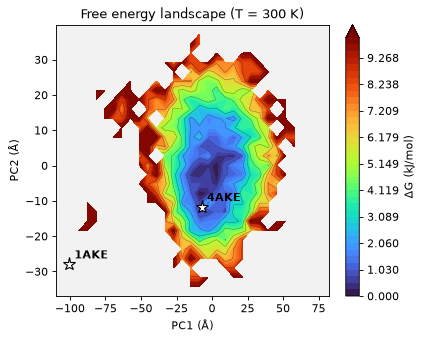

In [5]:
land = api.landscape(pcs, temperature=300.0, bins=30)
fig, ax, mappable = api.plot_landscape(land)
for name, (x, y) in crystal.items():
    ax.plot(x, y, marker="*", ms=12, mec="k", mfc="w")
    ax.annotate(name, (x, y), xytext=(5, 5), textcoords="offset points", weight="bold")
fig.set_size_inches(5.5, 4.4); fig.set_dpi(80)
plt.show()

## 4. States

Watershed segmentation of ΔG; basins separated by less than 1 kT are merged and basins holding
≥ 5 % of the frames are major states.

In [6]:
st = api.states(land, min_population=0.05)
display(st.populations().round(3))
print(f"unassigned / minor: {st.unassigned_population*100:.1f}%")

,state,population,min_cv1,min_cv2,min_free_energy_kJ_mol
0,State A,0.99,-8.858,-7.825,-0.0


unassigned / minor: 1.0%


## 5. Kinetics and convergence

In [7]:
kin = api.kinetics(st)
display(kin["dwell_summary"].round(2))
conv = api.convergence(ens, pcs, st)
print(conv.sampling_assessment)
for note in conv.assessment_notes:
    print(" -", note)

,state,visits,visits_uncensored,mean_dwell_ps,median_dwell_ps,max_dwell_ps,total_time_ps,transitions_out,transitions_in,lifetime_from_rate_ps
0,State A,1,0,NaN,NaN,995280.0,995280.0,0,0,inf


Good evidence of stability
 - Effective number of independent samples along PC1/PC2: 65 of 4187 frames (statistical inefficiency Rep_1: g=64.4 frames).
 - High subspace overlap between the first and second halves of the replicates (RMSIP = 0.89; heuristic: >= 0.70 high, 0.50-0.70 moderate, < 0.50 low).
 - Low PC1 cosine content (0.01 < 0.50): the dominant motion is not consistent with random diffusion.


## 6. Streaming PCA and the MDAnalysis `AnalysisBase` class

`conformatlas.streaming.streaming_pca` computes the same PCA in chunked passes without holding
the trajectory in memory. `ConformAtlasPCA` wraps the same accumulator in the MDAnalysis analysis
protocol.

In [8]:
from conformatlas.streaming import streaming_pca
from conformatlas.trajectory import load_reference_coordinates

ref_fit = load_reference_coordinates(TOPO, atom_indices=ens.fit_indices, fallback_trajectory=TRAJ)
with tempfile.TemporaryDirectory() as tmp:
    sp = streaming_pca(TOPO, [TRAJ], ens.atom_indices, fit_atom_indices=ens.fit_indices,
                       reference_fit_coords=ref_fit, n_components=10, chunk_size=500,
                       precision="float32", projection_store=Path(tmp) / "proj.npy", quiet=True)
    rel = np.max(np.abs(sp.eigenvalues - pcs.eigenvalues) / pcs.eigenvalues)
    print(f"streaming vs in-memory eigenvalues: max relative difference {rel:.1e}; "
          f"projections stored as {sp.projection_array.dtype} memmap {sp.projection_array.shape}")

from conformatlas.mda_analysis import ConformAtlasPCA
u = mda.Universe(str(TOPO), str(TRAJ))
mpca = ConformAtlasPCA(u.select_atoms("name CA"), n_components=5).run()
print("ConformAtlasPCA eigenvalues (no fit, Å²):", np.round(mpca.results.eigenvalues, 1))

streaming vs in-memory eigenvalues: max relative difference 4.5e-15; projections stored as float32 memmap (4187, 10)


ConformAtlasPCA eigenvalues (no fit, Å²): [361.2 140.   97.9  46.   31. ]


## 7. Full pipeline, HDF5 container and re-binning

`api.analyze` runs everything the CLI does (figures, report, bootstrap, representatives) and
returns the `AnalysisResults`. `save_results` writes one HDF5 file; `rebin` recomputes the
landscape and states on a new grid from the stored projections without redoing the PCA.

HDF5: 2275 kB; states restored: ['State A']
20 x 20 grid: [('State A', 0.995)]


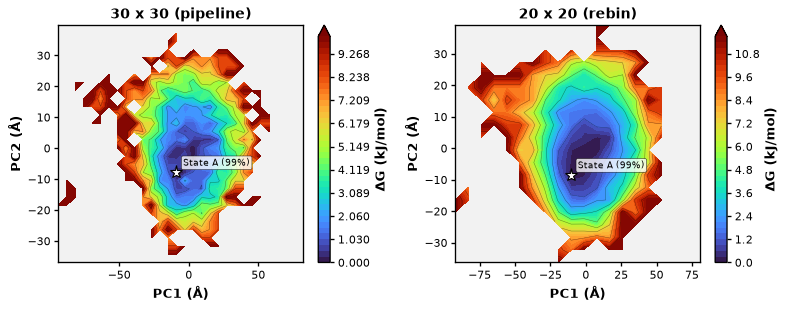

In [9]:
from conformatlas.results_io import save_results, load_results, rebin

workdir = Path(tempfile.mkdtemp(prefix="conformatlas_nb_"))
res = api.analyze(TOPO, [TRAJ], output_dir=workdir / "run", cov_group="C-alpha", lsq_group="C-alpha",
                  index_file=NDX, bins=30, n_bootstrap=50, interactive=False)
h5 = save_results(res, workdir / "results.h5")
back = load_results(h5)
print("HDF5:", h5.stat().st_size // 1024, "kB;", "states restored:", [s.label for s in back.states])

coarse = rebin(back, bins=20, smooth_sigma=0.0)
print("20 x 20 grid:", [(s.label, round(s.population, 3)) for s in coarse.states])
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=80)
api.plot_landscape(res, ax=axes[0]); axes[0].set_title("30 x 30 (pipeline)")
api.plot_landscape(coarse, ax=axes[1]); axes[1].set_title("20 x 20 (rebin)")
fig.tight_layout()
display(fig)  # explicit display, then close so that Jupyter does not show it twice
plt.close(fig)

### Caveats

* The trajectory leaves the closed state once, in the first tens of nanoseconds, and never
  returns. The landscape and the state population describe the open basin; the run carries no
  information on the closed-state population or on opening and closing rates.
* Successive frames are correlated: `conv.n_eff` gives the effective number of independent
  samples, far fewer than the 4,187 frames.
* The tutorial adds the domain-angle landscape, the Markov state model and a comparison with a
  known answer.